# Pratiksha Somnath Avhad

## Data Analytics – Level 2

### Task 2: Wine Quality Prediction

**Objective:**  
To build a Machine Learning model to predict wine quality based on its physicochemical properties.

**Tools & Technologies:**  
Python | Pandas | NumPy | Matplotlib | Seaborn | Scikit-learn | Jupyter Notebook

**Project Overview:**  
In this task, I will explore the wine quality dataset, perform data cleaning and preprocessing, visualize important features,
train a Machine Learning model to predict wine quality, and evaluate its performance using suitable evaluation metrics.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [4]:

import pandas as pd

df = pd.read_csv("winequality-red.csv", sep=";")

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()


Dataset loaded successfully!
Shape of dataset: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


**Observation:**

- The Wine Quality dataset was loaded successfully.
- The dataset contains **1,599 rows and 12 columns**.
- It includes 11 physicochemical properties of red wine and one target column, `quality`.
- The dataset is ready for further data exploration and preprocessing.

In [5]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Dataset Shape: (1599, 12)

Column Names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non

**Observation:**

- The dataset contains 1,599 rows and 12 columns.
- There are 11 numerical columns with the `float64` data type and one column, `quality`, with the `int64` data type.
- All 12 columns contain 1,599 non-null values.
- The dataset has no missing values, so no missing-value treatment is required at this stage.

In [4]:

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())


Missing Values in Each Column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total Missing Values: 0


**Observation:**

- The missing value analysis was performed on all columns.
- All 12 columns contain zero missing values.
- The total number of missing values in the dataset is **0**.
- Therefore, no missing value imputation is required for this dataset.

In [6]:

df.describe()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


**Observation:**

- The statistical summary provides the count, mean, standard deviation, minimum, maximum, and quartile values for all numerical columns.
- The average wine quality score is approximately **5.64**.
- The alcohol content ranges from **8.4 to 14.9**.
- The wine quality scores range from **3 to 8**.
- These statistics help us understand the distribution and variation of the dataset features.

In [7]:

print("Wine Quality Distribution:")
print(df["quality"].value_counts().sort_index())


Wine Quality Distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


**Observation:**

- The dataset contains wine quality scores ranging from 3 to 8.
- Quality score **5** has the highest number of samples, with 681 wines.
- Quality score **6** is the second most common, with 638 wines.
- Quality scores 3 and 8 have very few samples compared to the other categories.
- Most wine samples have quality scores of 5 or 6, indicating that the target classes are imbalanced.

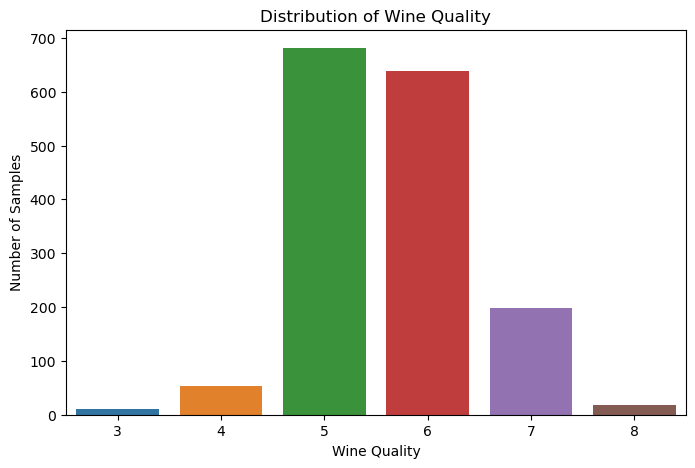

In [8]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="quality")

plt.title("Distribution of Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Samples")
plt.show()


**Observation:**

- The bar chart shows the distribution of wine quality scores from 3 to 8.
- Quality scores 5 and 6 have the highest number of samples.
- Quality score 5 is the most frequent, followed by quality score 6.
- Quality scores 3 and 8 have very few samples.
- The distribution indicates an imbalance among the quality classes, which should be considered during model evaluation.

In [9]:

correlation = df.corr(numeric_only=True)

print("Correlation with Wine Quality:")
print(correlation["quality"].sort_values(ascending=False))


Correlation with Wine Quality:
quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


**Observation:**

- Alcohol has the strongest positive correlation with wine quality, with a correlation coefficient of approximately **0.476**.
- Sulphates and citric acid also show positive correlations with wine quality.
- Volatile acidity has a negative correlation of approximately **-0.391** with wine quality.
- Density and total sulfur dioxide also show negative correlations with wine quality.
- These results indicate that alcohol and volatile acidity may be useful features for predicting wine quality. However, 
  correlation does not imply causation.

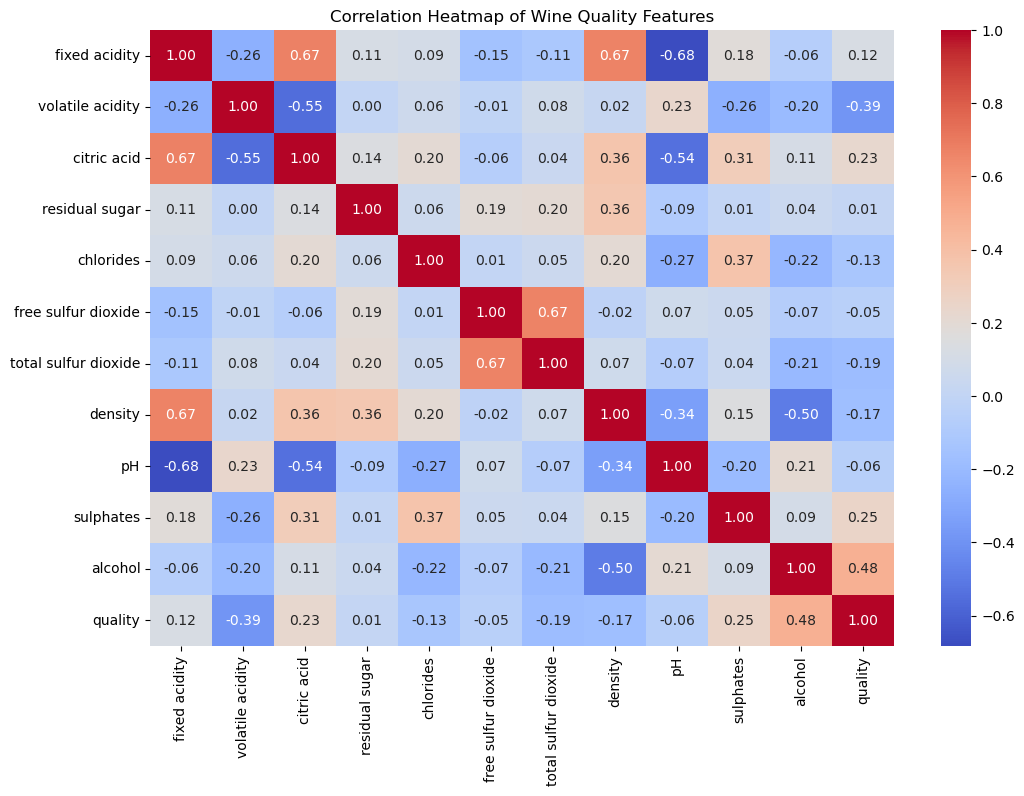

In [10]:

plt.figure(figsize=(12, 8))

sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm")

plt.title("Correlation Heatmap of Wine Quality Features")
plt.show()


**Observation:**

- The heatmap illustrates the correlation between all numerical features in the wine quality dataset.
- Alcohol shows the strongest positive correlation with wine quality, approximately **0.48**.
- Volatile acidity shows a negative correlation with wine quality, approximately **-0.39**.
- Sulphates and citric acid have positive correlations with wine quality.
- The heatmap helps identify relationships among features and supports feature selection for the Machine Learning model.

In [10]:

X = df.drop("quality", axis=1)
y = df["quality"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())


Features Shape: (1599, 11)
Target Shape: (1599,)

Feature Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


**Observation:**

- The input features (`X`) contain 1,599 rows and 11 physicochemical properties of wine.
- The target variable (`y`) contains 1,599 wine quality values.
- The `quality` column was separated from the input features because it is the variable to be predicted.
- The dataset is now ready for splitting into training and testing sets.

In [11]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Features Shape: (1279, 11)
Testing Features Shape: (320, 11)
Training Target Shape: (1279,)
Testing Target Shape: (320,)


**Observation:**

- The dataset was divided into training and testing sets using an 80:20 ratio.
- The training set contains **1,279 samples** with 11 input features.
- The testing set contains **320 samples** with 11 input features.
- Stratified splitting was used to preserve the distribution of wine quality classes as much as possible.
- The training data will be used to build the model, while the testing data will be used to evaluate its performance on
   unseen samples.

In [12]:

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


**Observation:**

- A Random Forest Classifier was successfully trained using the training dataset.
- The model uses 100 decision trees to learn patterns from the wine quality features.
- Class balancing was enabled to help address the imbalance in wine quality categories.
- The trained model is now ready to predict wine quality on the testing dataset.

In [13]:

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Quality": y_test.values,
    "Predicted Quality": y_pred
})

print("Wine Quality Predictions:")
display(results.head(10))


Wine Quality Predictions:


,Actual Quality,Predicted Quality
0,6,6
1,5,6
2,5,5
3,5,6
4,6,6
5,6,6
6,5,5
7,4,5
8,6,6
9,8,8


**Observation:**

- The trained Random Forest model successfully predicted wine quality scores for the testing dataset.
- The first 10 predictions show both correct and incorrect predictions.
- Some predicted quality scores match the actual values, while others differ.
- Model evaluation metrics will be used to measure the overall prediction performance.

In [14]:

accuracy = accuracy_score(y_test, y_pred)

print("Model Evaluation Results")
print("-------------------------")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Model Evaluation Results
-------------------------
Accuracy: 69.38%

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.74      0.77      0.76       136
           6       0.64      0.76      0.70       128
           7       0.76      0.47      0.58        40
           8       0.50      0.33      0.40         3

    accuracy                           0.69       320
   macro avg       0.44      0.39      0.41       320
weighted avg       0.67      0.69      0.68       320



**Observation:**

- The Random Forest model achieved an accuracy of **69.38%** on the test dataset.
- The model performed better in predicting wine quality classes 5 and 6, with F1-scores of 0.76 and 0.70, respectively.
- The model showed weaker performance for quality classes 3 and 4 because it could not correctly predict any samples from these classes.
- The weighted average F1-score was **0.68**, indicating moderate overall model performance.
- The classification report helps evaluate the model using precision, recall, F1-score, and support.

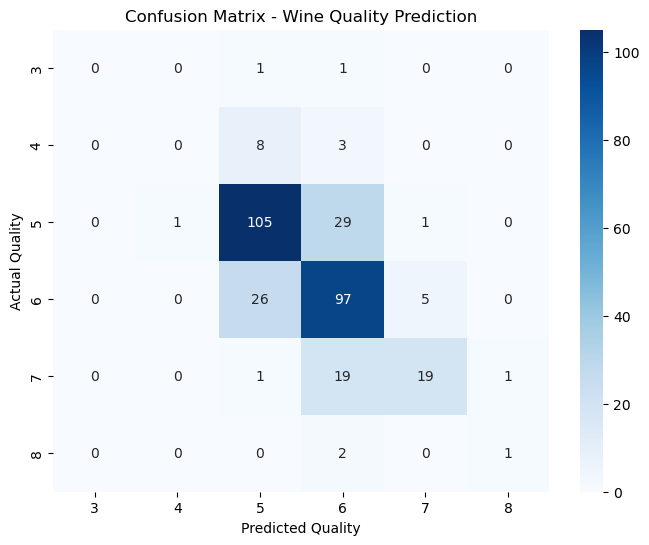

In [15]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - Wine Quality Prediction")
plt.xlabel("Predicted Quality")
plt.ylabel("Actual Quality")
plt.show()


**Observation:**

- The confusion matrix shows the actual and predicted wine quality scores of the testing dataset.
- The model correctly predicted **105 wines with quality 5** and **97 wines with quality 6**.
- The model frequently confused quality scores 5 and 6, indicating that these categories are difficult to distinguish.
- The model struggled to predict quality scores 3, 4, and 8 because these classes have very few samples.
- Overall, the confusion matrix helps identify the model's strengths and weaknesses across different wine quality categories.

Feature Importance:
alcohol                 0.140770
volatile acidity        0.131813
sulphates               0.123982
total sulfur dioxide    0.094395
density                 0.093580
citric acid             0.077590
chlorides               0.074129
pH                      0.073729
fixed acidity           0.065897
free sulfur dioxide     0.064391
residual sugar          0.059724
dtype: float64


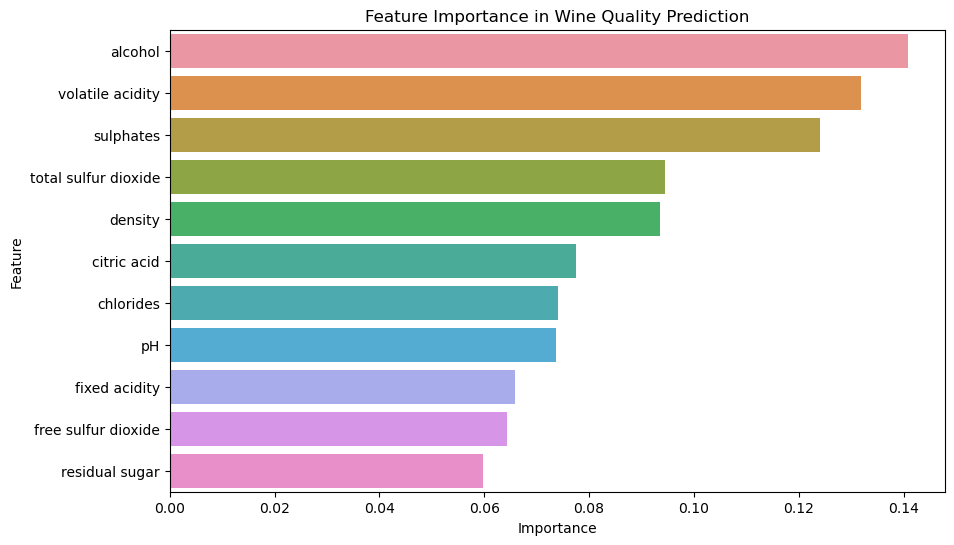

In [16]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index
)

plt.title("Feature Importance in Wine Quality Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

**Observation:**

- The feature importance analysis identifies the most influential features used by the Random Forest model for predicting
  wine quality.
- **Alcohol** is the most important feature, with an importance score of approximately **0.141**.
- **Volatile acidity** and **sulphates** are the second and third most important features, respectively.
- **Residual sugar** has the lowest feature importance among the 11 input features.
- These results help us understand which features contribute most to the model's predictions. Feature importance indicates the
  model's reliance on features, but it does not establish a causal relationship with wine quality.

## Conclusion

In this task, I developed a Wine Quality Prediction model using the Random Forest Classifier.

- Explored the wine quality dataset containing **1,599 rows and 12 columns**.
- Checked missing values and analyzed the statistical summary of the dataset.
- Visualized wine quality distribution and feature correlations.
- Split the dataset into training and testing sets using an 80:20 ratio.
- Trained a Random Forest Classifier and achieved an accuracy of **69.38%**.
- Evaluated model performance using a classification report and confusion matrix.
- Identified alcohol, volatile acidity, and sulphates as the top three important features.

**Learning Outcome:**

This task helped me understand data exploration, visualization, classification, model evaluation, and feature importance using 
  Python and Scikit-learn.